softmax : 다중분류
expit : 이진분류

In [9]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier

In [ ]:
#데이터 불러오기
df =pd.read_csv('data/wine.csv')
df.head()

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0
3,9.8,1.9,3.16,0.0
4,9.4,1.9,3.51,0.0


In [19]:
#전처리
# 훈련데이터와 테스트 데이터 분리
data = df[df.columns[:-1]].values
label = df['class'].values

train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [20]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [ ]:
#데이터 학습
sc= SGDClassifier(loss = 'log_loss',random_state=42)
train_score = []
test_score = []

classes = np.unique(train_label)
for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

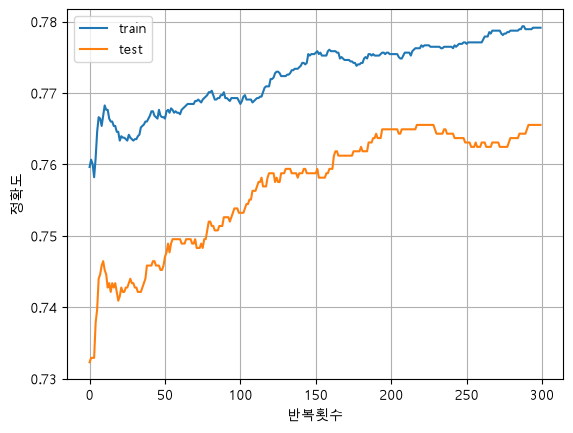

In [15]:
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(['train','test'])
plt.show()

In [22]:
sc =SGDClassifier(loss = 'log_loss',max_iter=300,tol=None,random_state=42)
sc.fit(train_scaled,train_label)
print('train정확도:',sc.score(train_scaled,train_label))
print('test정확도:',sc.score(test_scaled,test_label))

train정확도: 0.7820197044334976
test정확도: 0.7661538461538462
